# 04 · Calibration / holdout split

Шаг 5 плана. Одна переменная `cutoff_date = 2010-12-01`: калибровка — `date < cutoff`,
holdout — `cutoff <= date < cutoff + 12 мес`. Holdout наблюдается полностью; неполный
декабрь 2011 исключён, ноябрьский пик входит в оба окна. Признаки строятся только по
калибровке, таргет — только по holdout.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

cal, hold = split_transactions(tx)
feats = calibration_features(tx)
rev_cal = calibration_revenue(tx)
target = build_target(tx, feats.index)
first = first_purchase_dates(tx)
end = CUTOFF_DATE + pd.DateOffset(months=HORIZON_MONTHS)
new_hold = first[(first >= CUTOFF_DATE) & (first < end)].index
after = first[first >= end].index
print('калибровка:', cal.shape, '· holdout:', hold.shape)
print('клиентов:', len(feats), '· новых в holdout:', len(new_hold), '· после holdout:', len(after))
print('период калибровки:', cal.date.min(), '→', cal.date.max())
print('период holdout:', hold.date.min(), '→', hold.date.max())
assert feats.index.equals(first[first < CUTOFF_DATE].index)


калибровка: (393869, 10) · holdout: (382342, 10)
клиентов: 4239 · новых в holdout: 1585 · после holdout: 28
период калибровки: 2009-12-01 07:45:00 → 2010-11-30 19:35:00
период holdout: 2010-12-01 08:26:00 → 2011-11-30 17:42:00


## Проверка §5а-2: frequency в holdout — из сырых транзакций

`frequency_holdout` не выводится из калибровочной `frequency` и не берётся из
производной колонки: это число уникальных дней с покупкой в holdout минус один.

In [2]:
hold_sales = hold[~hold.is_cancel]
raw_days = (hold_sales.assign(day=hold_sales.date.dt.normalize())
            .groupby('customer_id')['day'].nunique()
            .reindex(feats.index, fill_value=0))
raw_freq = (raw_days - 1).clip(lower=0).astype('int64')
assert (raw_freq == target.frequency_holdout).all(), 'holdout frequency не совпала с сырыми днями'
assert not (target.frequency_holdout == feats.frequency).all(), 'holdout и калибровка перепутаны'
print('ok: frequency holdout пересобрана из сырых транзакций')
print('доля frequency_holdout = 0:', f'{(target.frequency_holdout == 0).mean():.1%}')


ok: frequency holdout пересобрана из сырых транзакций
доля frequency_holdout = 0: 55.2%


## Отмены раньше первой покупки

557 строк с датой раньше первой покупки клиента — это возвраты покупок, сделанных до
начала окна. Строки не удаляются из `transactions.parquet`, но исключаются из
lifecycle-расчётов и в калибровке, и в holdout. Правило одно на оба окна.

In [3]:
pre = pre_first_mask(tx)
assert int(pre.sum()) == 557 and int((pre & tx.is_cancel).sum()) == 557
hold_pre = pre & (tx.date >= CUTOFF_DATE) & (tx.date < end)
print('строк до первой покупки:', int(pre.sum()), '· из них в holdout:', int(hold_pre.sum()))
print('net-выручка калибровки:', round(rev_cal.sum()), '£ · holdout:', round(target.revenue_holdout.sum()), '£')


строк до первой покупки:

 557 · из них в holdout: 3
net-выручка калибровки: 8103688 £ · holdout: 6525285 £


## Сохранение split

In [4]:
split = (feats.join(target).join(rev_cal.rename('revenue_cal')))
split['country'] = customer_country(tx)
split['cohort'] = split.first_purchase.dt.to_period('M').astype(str)
split['age_days'] = (CUTOFF_DATE - split.first_purchase).dt.days
split.to_parquet(PROCESSED / 'ltv_split.parquet')
meta = {
    'cutoff_date': str(CUTOFF_DATE.date()),
    'holdout_end': str(end.date()),
    'horizon_months': HORIZON_MONTHS,
    'calibration_customers': int(len(split)),
    'new_in_holdout': int(len(new_hold)),
    'after_holdout': int(len(after)),
    'pre_first_rows': int(pre.sum()),
    'pre_first_in_holdout': int(hold_pre.sum()),
    'holdout_revenue': float(target.revenue_holdout.sum()),
}
(PROCESSED / 'ltv_split_meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
meta


{'cutoff_date': '2010-12-01',
 'holdout_end': '2011-12-01',
 'horizon_months': 12,
 'calibration_customers': 4239,
 'new_in_holdout': 1585,
 'after_holdout': 28,
 'pre_first_rows': 557,
 'pre_first_in_holdout': 3,
 'holdout_revenue': 6525284.84}

## График окна

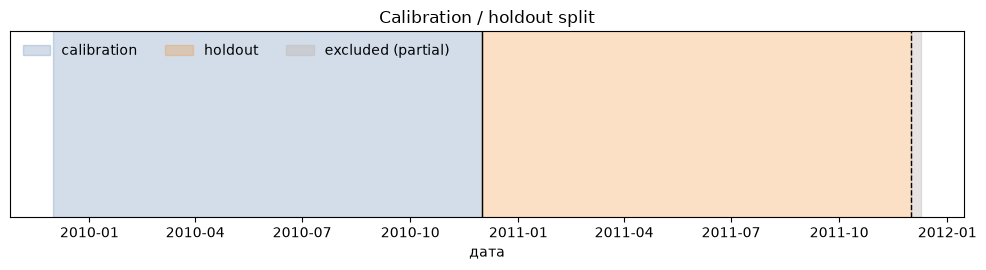

In [5]:
plot_split_timeline(tx, CUTOFF_DATE, end, FIG / '07-split-timeline.png')
plt.show()


Слева калибровка (12 мес), в центре holdout (12 мес), справа исключённый хвост
2011-12-01…09. Holdout заканчивается 2011-11-30, поэтому ноябрьский пик попал в него
целиком, а неполный декабрь не разбавляет таргет.